# 04 · Caracterización e interpretación de los perfiles
Aquí los grupos numéricos se convierten en **perfiles ciudadanos**: se describen con edad, sexo, región, tipo de sección e historial de participación, se nombran y se exportan tablas y fichas preliminares para el documento y la infografía.

## Cómo leer los **índices de composición**
`índice = (% del grupo en la categoría) / (% de toda la base en la categoría) × 100`.
Ejemplo: si el 30 % de la lista nominal del perfil *P* son jóvenes y en toda la base los jóvenes son el 20 %, el índice es 30/20 × 100 = **150** → los jóvenes están **sobrerrepresentados 1.5×** en *P*. Un índice de 100 significa que el perfil se parece al promedio; < 100, subrepresentado.

## ⚠️ Falacia ecológica (decláralo en la metodología)
Los datos son **agregados**: los perfiles describen **segmentos** (territorio × sexo × edad), no personas individuales.
Que un segmento "joven-intermitente" exista no implica que cada joven de ese segmento se comporte así.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import utils as U

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.3f}".format

FUENTE = (U.DIR_PROC / "FUENTE.txt").read_text()
if FUENTE != "REAL":
    print("⚠️  DATOS SINTÉTICOS: no uses estos resultados en el entregable. ⚠️")
u = pd.read_csv(U.DIR_PROC / "unidades_con_cluster.csv")
ANIOS = sorted(int(c.replace("tasa_", "")) for c in u.columns if c.startswith("tasa_") and c.replace("tasa_", "").isdigit())
COLS_TASA = [f"tasa_{a}" for a in ANIOS]
ANIOS = ANIOS
COLS_TASA = COLS_TASA
K = u["cluster"].nunique()
PESO = "ln_media"          # peso = tamaño del segmento (aprox. personas en lista nominal)
PALETA = sns.color_palette("viridis", K)
print(f"{len(u):,} segmentos | {K} perfiles")

24,110 segmentos | 4 perfiles


## 1. Tamaño y trayectoria de participación
Las medias se **ponderan por tamaño** (`ln_media`) para que reflejen personas, no segmentos.

In [2]:
cols_extra = ["tasa_media", "tasa_pres", "tasa_interm", "brecha_pres_interm", "volatilidad", "tendencia"]
res = U.media_ponderada(u, COLS_TASA + cols_extra, PESO, "cluster")
res.insert(0, "n_segmentos", u.groupby("cluster").size())
res.insert(1, "%_lista_nominal", u.groupby("cluster")[PESO].sum() / u[PESO].sum() * 100)
nacional = U.media_ponderada(u.assign(g=1), COLS_TASA + cols_extra, PESO, "g").iloc[0]
res

,n_segmentos,%_lista_nominal,tasa_2009,tasa_2012,tasa_2015,tasa_2018,tasa_2021,tasa_2024,tasa_media,tasa_pres,tasa_interm,brecha_pres_interm,volatilidad,tendencia
cluster,,,,,,,,,,,,,,
0,4298,19.517,0.274,0.457,0.271,0.428,0.321,0.381,0.355,0.422,0.288,0.133,0.088,0.003
1,6296,31.406,0.387,0.582,0.385,0.542,0.434,0.500,0.472,0.541,0.402,0.139,0.093,0.003
2,7700,29.453,0.495,0.684,0.505,0.632,0.554,0.608,0.579,0.641,0.518,0.123,0.087,0.003
3,5816,19.623,0.600,0.766,0.622,0.724,0.672,0.719,0.684,0.736,0.631,0.105,0.074,0.004


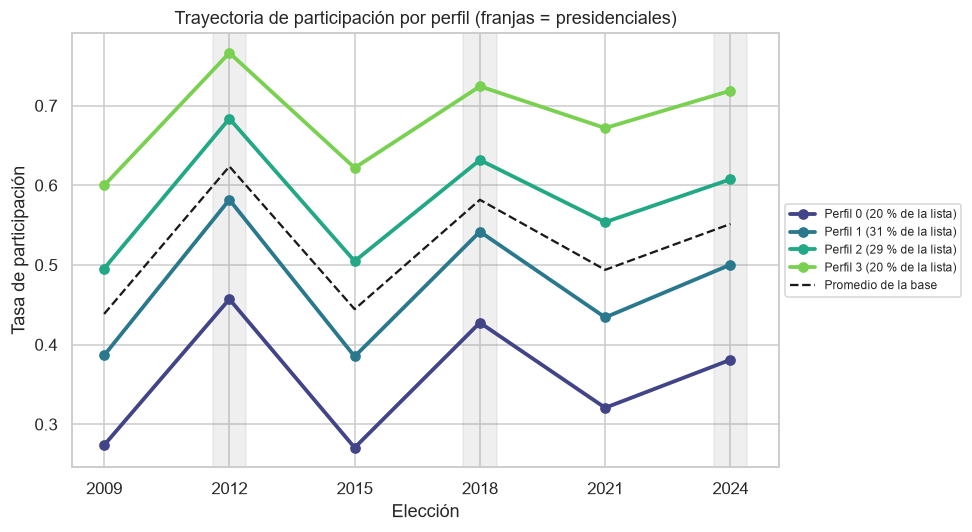

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
for c in range(K):
    ax.plot(ANIOS, res.loc[c, COLS_TASA].values, marker="o", lw=2.5, color=PALETA[c],
            label=f"Perfil {c} ({res.loc[c, '%_lista_nominal']:.0f} % de la lista)")
ax.plot(ANIOS, nacional[COLS_TASA].values, "k--", lw=1.5, label="Promedio de la base")
for a in [a for a in ANIOS if a in [2012, 2018, 2024]]:
    ax.axvspan(a - .4, a + .4, color="gray", alpha=.12)
ax.set(title="Trayectoria de participación por perfil (franjas = presidenciales)", xlabel="Elección", ylabel="Tasa de participación", xticks=ANIOS)
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1, .5)); plt.tight_layout()
plt.savefig(U.DIR_FIG / "trayectorias_perfiles.png", dpi=200, bbox_inches="tight"); plt.show()

## 2. Composición sociodemográfica de cada perfil
Se calcula el **porcentaje de la lista nominal** del perfil en cada categoría y su **índice** respecto a la base completa.

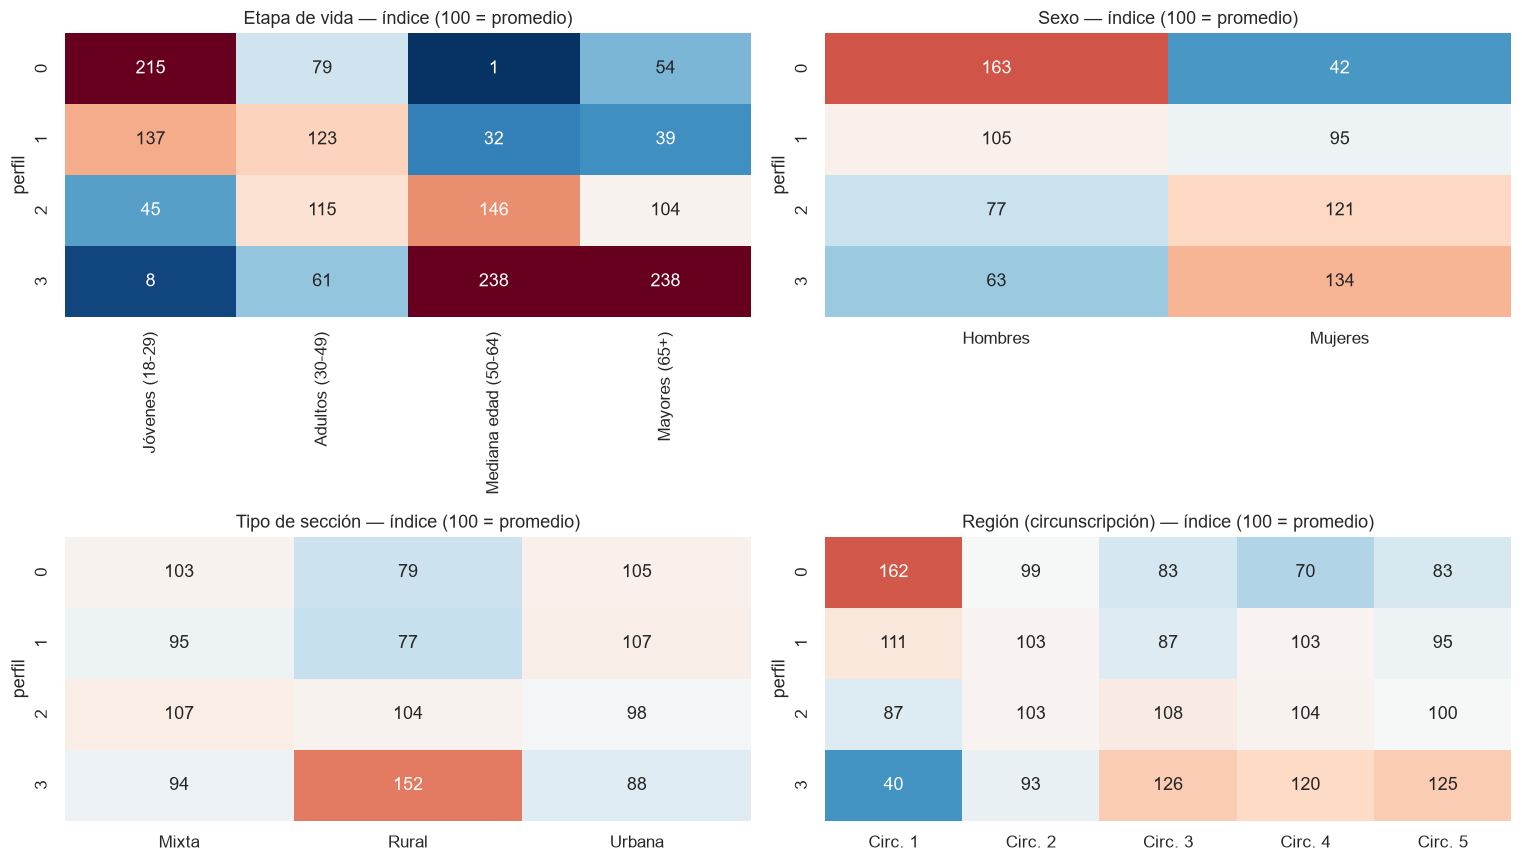

In [4]:
def composicion(var):
    t = u.pivot_table(index="cluster", columns=var, values=PESO, aggfunc="sum", fill_value=0)
    pct = t.div(t.sum(axis=1), axis=0) * 100                 # % dentro de cada perfil
    base = t.sum(axis=0) / t.values.sum() * 100               # % en toda la base
    idx = pct.div(base, axis=1) * 100                         # índice (100 = promedio)
    return pct, idx

comp = {v: composicion(v) for v in ["ciclo_vida", "sexo", "tipo_seccion", "region"]}
comp["ciclo_vida"] = tuple(d[[c for c in U.ORDEN_CICLO if c in d.columns]] for d in comp["ciclo_vida"])

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (v, titulo) in zip(axes.ravel(), [("ciclo_vida", "Etapa de vida"), ("sexo", "Sexo"), ("tipo_seccion", "Tipo de sección"), ("region", "Región (circunscripción)")]):
    sns.heatmap(comp[v][1], annot=True, fmt=".0f", cmap="RdBu_r", center=100, vmin=0, vmax=200, ax=ax, cbar=False)
    ax.set(title=f"{titulo} — índice (100 = promedio)", ylabel="perfil", xlabel="")
plt.tight_layout(); plt.savefig(U.DIR_FIG / "indices_composicion.png", dpi=200, bbox_inches="tight"); plt.show()

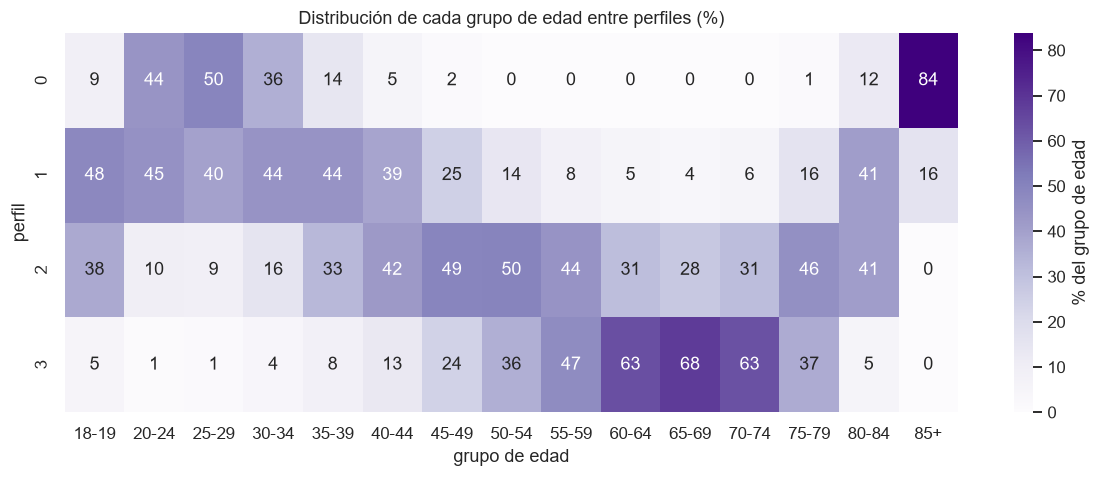

In [5]:
# ¿A qué perfil tiende a pertenecer cada grupo de edad? (cada columna suma 100 %)
orden_edad = U.orden_grupos_edad(u["grupo_edad"])
t = u.pivot_table(index="cluster", columns="grupo_edad", values=PESO, aggfunc="sum", fill_value=0)[orden_edad]
dist_edad = t.div(t.sum(axis=0), axis=1) * 100
plt.figure(figsize=(11, 4.5))
sns.heatmap(dist_edad, annot=True, fmt=".0f", cmap="Purples", cbar_kws={"label": "% del grupo de edad"})
plt.title("Distribución de cada grupo de edad entre perfiles (%)"); plt.ylabel("perfil"); plt.xlabel("grupo de edad")
plt.tight_layout(); plt.savefig(U.DIR_FIG / "edad_vs_perfil.png", dpi=200, bbox_inches="tight"); plt.show()

## 3. Nombres de los perfiles
La función genera un **nombre sugerido** con reglas simples:
- **Nivel**: compara la participación media del perfil con la de la base en unidades de desviación estándar (z > 0.5 alta; z < −0.5 baja).
  Ejemplo: base 0.52 con desviación 0.10; perfil con 0.64 → z = 1.2 → **alta**.
- **Patrón**: brecha presidencial–intermedia ±0.02 respecto a la base ("más selectiva" / "más estable").
- **Tendencia**: pendiente > +0.01 por elección "al alza"; < −0.01 "a la baja".

Son solo sugerencias: **escribe nombres narrativos propios** en `NOMBRES` (p. ej. *"Los Constantes"*, *"Jóvenes de ocasión"*), apoyándote en las tablas y gráficas de arriba.

In [6]:
glob_mu = np.average(u["tasa_media"], weights=u[PESO]); glob_sd = u["tasa_media"].std()

def sugerir_nombre(c):
    z = (res.loc[c, "tasa_media"] - glob_mu) / glob_sd
    nivel = "alta" if z > .5 else "baja" if z < -.5 else "media"
    dif = res.loc[c, "brecha_pres_interm"] - nacional["brecha_pres_interm"]
    patron = "más selectiva (sube en presidenciales)" if dif > .02 else "más estable entre elecciones" if dif < -.02 else "patrón promedio"
    t = res.loc[c, "tendencia"]
    tend = "al alza" if t > .01 else "a la baja" if t < -.01 else "sin tendencia clara"
    return f"Participación {nivel}, {patron}, {tend}"

SUGERIDOS = {c: sugerir_nombre(c) for c in range(K)}
NOMBRES = {
    # 0: "Nombre narrativo del perfil 0",
    # 1: "...",
}
nombre = {c: NOMBRES.get(c, f"Perfil {c}: {SUGERIDOS[c]}") for c in range(K)}
pd.Series(nombre, name="nombre")

0    Perfil 0: Participación baja, patrón promedio,...
1    Perfil 1: Participación media, patrón promedio...
2    Perfil 2: Participación media, patrón promedio...
3    Perfil 3: Participación alta, más estable entr...
Name: nombre, dtype: str

## 4. Fichas preliminares por perfil (insumo para la infografía)
Cada ficha resume: trayectoria vs. base, composición por edad y región. Son **borradores analíticos**; el diseño final (iconos, narrativa) lo haces después.

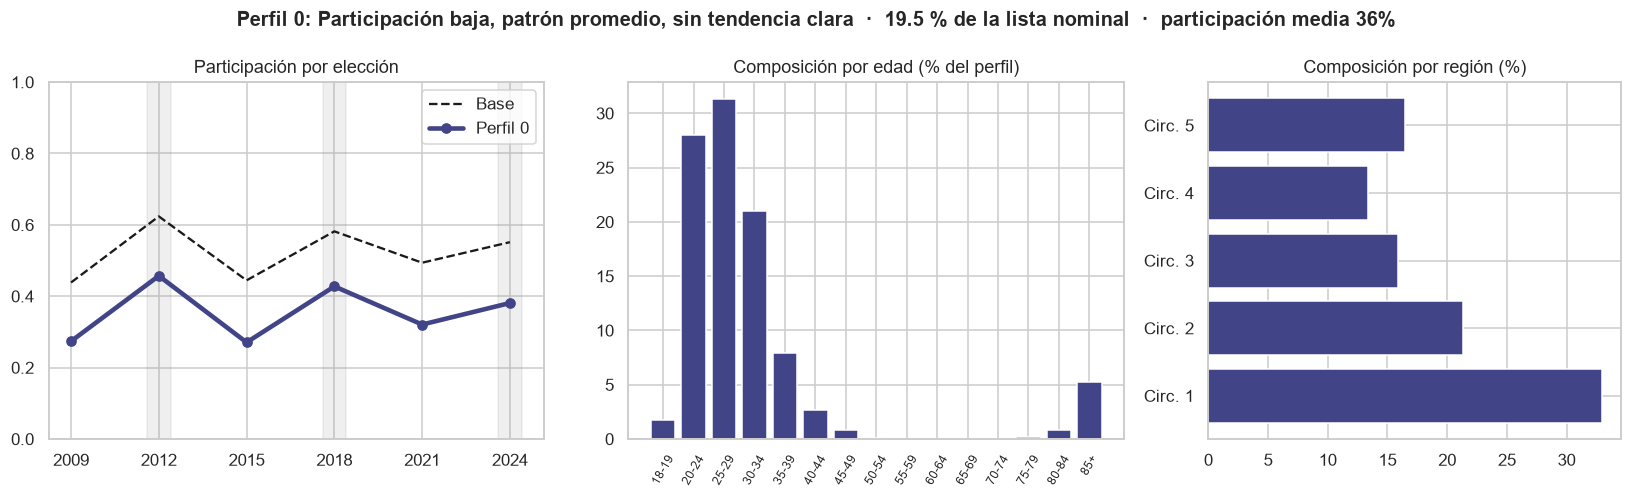

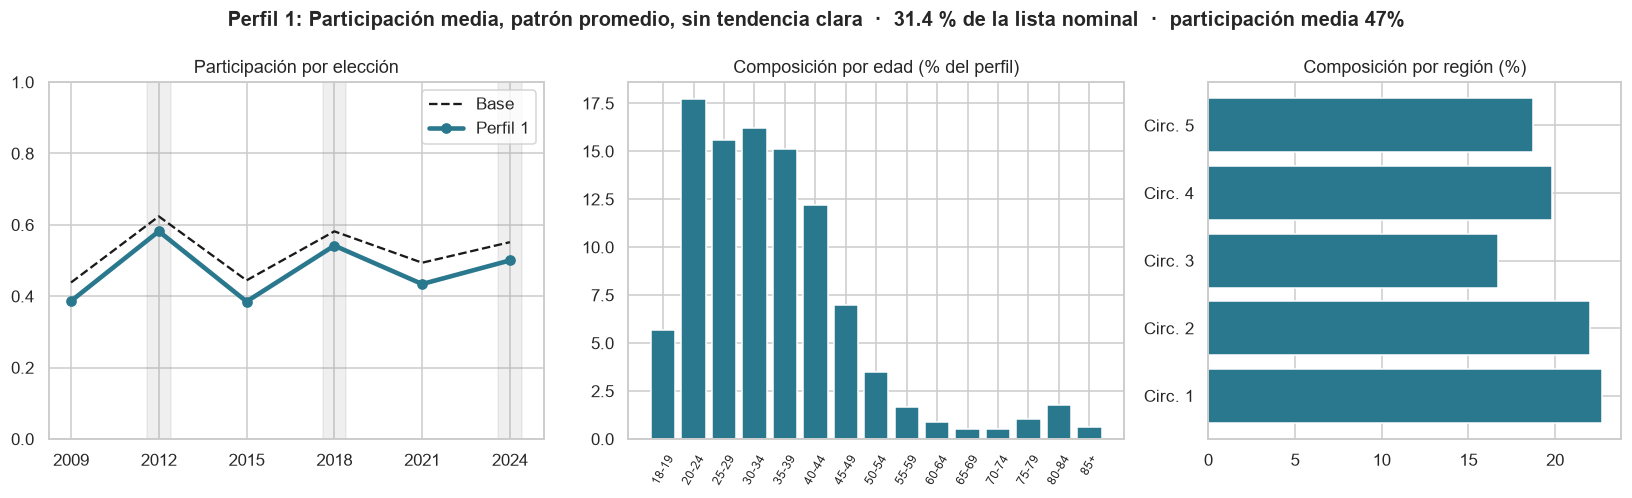

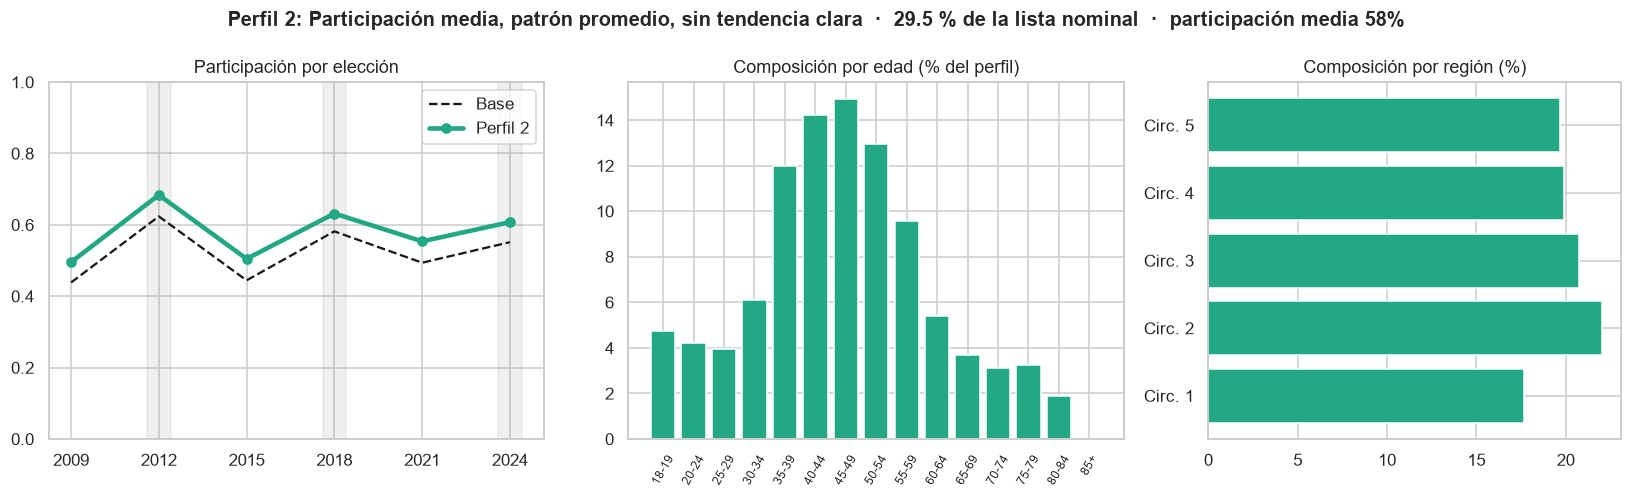

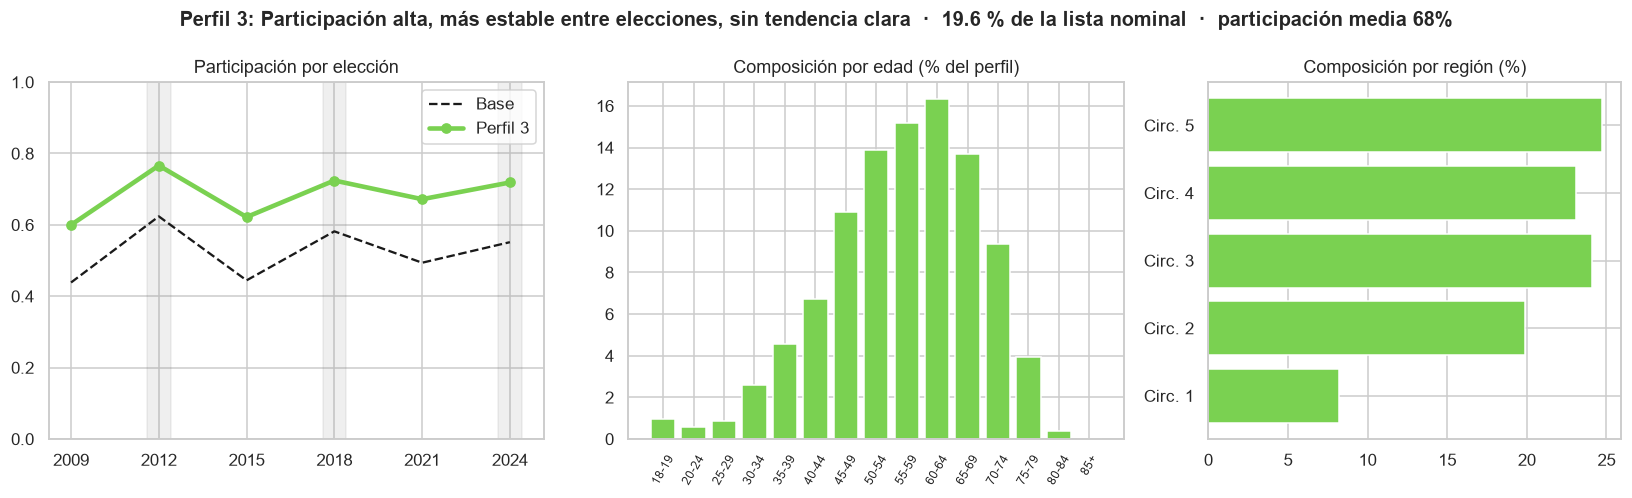

In [7]:
def ficha(c):
    fig = plt.figure(figsize=(15, 4.6))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.2, 1.2, 1])
    ax1, ax2, ax3 = (fig.add_subplot(g) for g in gs)

    ax1.plot(ANIOS, nacional[COLS_TASA].values, "k--", label="Base")
    ax1.plot(ANIOS, res.loc[c, COLS_TASA].values, "o-", lw=3, color=PALETA[c], label=f"Perfil {c}")
    for a in [a for a in ANIOS if a in [2012, 2018, 2024]]: ax1.axvspan(a - .4, a + .4, color="gray", alpha=.12)
    ax1.set(title="Participación por elección", xticks=ANIOS, ylim=(0, 1)); ax1.legend()

    ax2.bar(range(len(orden_edad)), t.loc[c, orden_edad].values / t.loc[c].sum() * 100, color=PALETA[c])
    ax2.set_xticks(range(len(orden_edad))); ax2.set_xticklabels(orden_edad, rotation=60, fontsize=8)
    ax2.set(title="Composición por edad (% del perfil)")

    r = comp["region"][0].loc[c]
    ax3.barh(r.index, r.values, color=PALETA[c]); ax3.set(title="Composición por región (%)")

    fig.suptitle(f"{nombre[c]}  ·  {res.loc[c, '%_lista_nominal']:.1f} % de la lista nominal  ·  participación media {res.loc[c, 'tasa_media']:.0%}",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    fig.savefig(U.DIR_FIG / f"ficha_perfil_{c}.png", dpi=200, bbox_inches="tight")
    plt.show()

for c in range(K):
    ficha(c)

## 5. Exportar tablas para el documento técnico y el repositorio

In [8]:
resumen = res.copy(); resumen.insert(0, "nombre", pd.Series(nombre))
resumen.to_csv(U.DIR_TAB / "perfil_resumen.csv")
for v, (pct, idx) in comp.items():
    pct.to_csv(U.DIR_TAB / f"composicion_{v}_pct.csv"); idx.to_csv(U.DIR_TAB / f"composicion_{v}_indice.csv")
dist_edad.to_csv(U.DIR_TAB / "distribucion_edad_por_perfil.csv")
u.assign(perfil=u["cluster"].map(nombre)).to_csv(U.DIR_PROC / "segmentos_con_perfil.csv", index=False)
print("Tablas en:", U.DIR_TAB); print("Figuras en:", U.DIR_FIG)

Tablas en: C:\Users\Pro12\Desktop\INE\outputs\tablas
Figuras en: C:\Users\Pro12\Desktop\INE\outputs\figuras


## 6. Siguientes pasos
1. Ajusta `K_FINAL` (notebook 03) si algún perfil resulta pequeño o poco interpretable, y vuelve a correr el 04.
2. Escribe los nombres y descripciones narrativas (sección 3) y **una estrategia diferenciada por perfil** (qué mensaje, canal y momento).
3. Redacta el documento técnico (8-12 cuartillas): datos, metodología, selección de k, perfiles, estrategias, limitaciones (falacia ecológica, cohortes, datos agregados).
4. Rediseña las fichas (sección 4) como infografía final (PDF/PNG alta resolución).